# 03 · Selección de la técnica de modelado (tarea 2.1, CRISP-DM fase 4)

Se comparan, **solo en el conjunto de VALIDACIÓN** (el de prueba no se toca), cinco variantes bajo el mismo protocolo de verificación 1 a 1:

| Variante | Tipo | Vector por imagen |
|---|---|---|
| (a1) CNN propia | CNN entrenada desde cero como clasificador de las 24 registradas | embedding de 128 (penúltima capa) |
| (a2) ResNet-18 por transferencia | preentrenada en **ImageNet** (objetos, no rostros), ajustada como clasificador de las 24 registradas | 512 tras el pooling |
| (b1) FaceNet VGGFace2 | InceptionResnetV1 preentrenada en rostros, **sin reentrenar** | 512 |
| (b2) FaceNet CASIA-WebFace | ídem, otros pesos | 512 |
| (c) LBPH | línea base clásica (OpenCV) | histogramas LBP 8×8 |

**Protocolo:**
- La plantilla de cada registrada es la media de los embeddings de sus fotos de **train**; en LBPH se usa el vecino más cercano entre sus fotos de train.
- Las comparaciones **genuinas** son cada foto de validación de una registrada contra su propia plantilla (305).
- Las comparaciones **impostoras** son cada foto de validación de las 3 impostoras contra las 24 plantillas (269 × 24 = 6 456).
- Como dato complementario se calculan impostores **internos**: cada registrada de validación contra las otras 23 plantillas.
- Se usa similitud **coseno**. Con vectores L2-normalizados, la distancia euclídea cumple d² = 2 − 2·cos, así que produce exactamente la misma curva ROC.

En esta tarea **no se ajusta nada**: (a1) y (a2) se entrenan con hiperparámetros fijos y un número fijo de épocas. La validación solo se usa
para registrar la curva de aprendizaje, no para elegir época. El ajuste de parámetros es la tarea 2.3.

In [1]:
import sys, time, copy, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, cv2
from src import config as C, data as D, models as M, metrics as MT, verification as V
torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
np.random.seed(C.SEED); torch.manual_seed(C.SEED)
DEV = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", DEV, torch.cuda.get_device_name(0) if DEV == "cuda" else "", "| torch", torch.__version__, "| TORCH_HOME", C.os.environ["TORCH_HOME"])
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e6", "axes.axisbelow": True})
COL = {"a1_cnn_propia": "#2a78d6", "a2_resnet18_imagenet": "#eb6834", "b1_facenet_vggface2": "#1baf7a",
       "b2_facenet_casia": "#eda100", "c_lbph": "#e87ba4"}
LS = {"a1_cnn_propia": "-", "a2_resnet18_imagenet": "--", "b1_facenet_vggface2": "-", "b2_facenet_casia": "-.", "c_lbph": ":"}
NOMBRE = {"a1_cnn_propia": "(a1) CNN propia", "a2_resnet18_imagenet": "(a2) ResNet-18 ImageNet",
          "b1_facenet_vggface2": "(b1) FaceNet VGGFace2", "b2_facenet_casia": "(b2) FaceNet CASIA", "c_lbph": "(c) LBPH"}

Dispositivo: cuda NVIDIA GeForce RTX 5060 | torch 2.11.0+cu128 | TORCH_HOME D:\IA\FaceID\models\torch_hub


## 1. Datos (división del cuaderno 02)

In [2]:
sp = D.load_split_table()
cache = np.load(C.DATA_PROCESSED / "faces160.npz", allow_pickle=True)
pos = {f: k for k, f in enumerate(cache["filename"])}
X_all = cache["X"]
REG = sorted(sp.loc[sp.role == "registrada", "person"].unique())
cls = {p: k for k, p in enumerate(REG)}
tr = sp[sp.split == "train"].reset_index(drop=True)
va = sp[sp.split == "val"].reset_index(drop=True)
assert (tr.role == "registrada").all() and (va.split == "val").all()
X_tr = X_all[[pos[f] for f in tr.filename]]; y_tr = tr.person.map(cls).values
X_va = X_all[[pos[f] for f in va.filename]]
va_reg = va.role == "registrada"
X_mon, y_mon = X_va[va_reg.values], va.loc[va_reg, "person"].map(cls).values
print(f"train: {len(tr)} imágenes de {tr.person.nunique()} registradas")
print(f"val: {va_reg.sum()} genuinas (24 registradas) + {(~va_reg).sum()} de impostoras ({', '.join(sorted(va.loc[~va_reg,'person'].unique()))})")
print("El conjunto de prueba NO se carga en este cuaderno.")
RES, SCORES, TIEMPOS, HIST = {}, {}, {}, {}

train: 1362 imágenes de 24 registradas
val: 305 genuinas (24 registradas) + 269 de impostoras (Andy Samberg, Elizabeth Olsen, Henry Cavill)
El conjunto de prueba NO se carga en este cuaderno.


In [3]:
def evaluar(nombre, S):
    """S: matriz (n_val, 24). Calcula métricas del protocolo y guarda puntuaciones."""
    sc = V.split_scores(S, va.person.values, va.role.values, REG)
    r = MT.summary(sc["genuinas"], sc["impostoras"])
    lo, hi = MT.bootstrap_eer(sc["genuinas"], sc["impostoras"])
    r.update({"EER_IC95_inf": lo, "EER_IC95_sup": hi,
              "EER_internas": MT.eer(sc["genuinas"], sc["internas"])[0],
              "FAR_internas_en_umbral": MT.far_frr(sc["genuinas"], sc["internas"], r["umbral"])[0]})
    RES[nombre], SCORES[nombre] = r, (S, sc)
    print(f"{NOMBRE[nombre]}: EER {r['EER']*100:.2f} % [IC95 {lo*100:.2f}-{hi*100:.2f}] | AUC {r['AUC']:.4f} | "
          f"umbral {r['umbral']:.4f} -> FAR {r['FAR']*100:.2f} %, FRR {r['FRR']*100:.2f} % | EER internas {r['EER_internas']*100:.2f} %")

def cronometrar(nombre, verificar, n=60, warm=5):
    """Tiempo por verificación de punta a punta: leer el JPG del disco, preprocesar, extraer el vector y compararlo
    con la plantilla reclamada. Mediana de n repeticiones tras calentar. No incluye detección de rostro (Faces ya viene recortado)."""
    paths = va.filename.map(lambda f: str(C.FACES_DIR / f)).values
    rng = np.random.default_rng(C.SEED); idx = rng.choice(len(paths), n + warm)
    t = []
    for j, i in enumerate(idx):
        t0 = time.perf_counter(); verificar(paths[i], j % len(REG)); dt = time.perf_counter() - t0
        if j >= warm: t.append(dt)
    return float(np.median(t) * 1000), float(np.percentile(t, 95) * 1000)

## 2. (c) Línea base LBPH

In [4]:
t0 = time.time()
G_tr, G_va = M.to_gray(X_tr), M.to_gray(X_va)
H_tr, H_va = M.lbph_histograms(G_tr), M.lbph_histograms(G_va)
S = V.lbph_matrix(H_va, H_tr, tr.person.values, REG, M.chi2_dist)
print(f"Histogramas: {H_tr.shape[1]} dimensiones | tiempo total {time.time()-t0:.1f} s")
evaluar("c_lbph", S)
Htr_by = {k: H_tr[tr.person.values == p] for k, p in enumerate(REG)}
def ver_lbph(path, k):
    g = cv2.cvtColor(D.read_rgb(path), cv2.COLOR_RGB2GRAY)
    return -M.chi2_dist(M.lbph_histograms([g]), Htr_by[k]).min()
TIEMPOS["c_lbph"] = {"CPU": cronometrar("c_lbph", ver_lbph)}
print("Tiempo por verificación (CPU, ms, mediana/p95):", TIEMPOS["c_lbph"]["CPU"])

Histogramas: 16384 dimensiones | tiempo total 274.8 s


(c) LBPH: EER 33.52 % [IC95 30.17-36.39] | AUC 0.7171 | umbral -33.0850 -> FAR 33.60 %, FRR 33.44 % | EER internas 28.55 %


Tiempo por verificación (CPU, ms, mediana/p95): (25.389250000444008, 37.1976999994331)


## 3. (b) FaceNet preentrenado (sin reentrenar)

Pesos de facenet-pytorch 2.6.0 (https://github.com/timesler/facenet-pytorch/releases), convertidos de los modelos de David Sandberg (davidsandberg/facenet): `20180402-114759-vggface2.pt` y `20180408-102900-casia-webface.pt`.

In [5]:
def embedding_scores(nombre, model, norm):
    E_tr = M.embed(model, X_tr, norm, DEV); E_va = M.embed(model, X_va, norm, DEV)
    T = V.templates(E_tr, tr.person.values, REG)
    evaluar(nombre, V.cosine_matrix(E_va, T))
    return T

def tiempos_embedding(nombre, model, norm, T):
    out = {}
    for dev in (["cuda"] if DEV == "cuda" else []) + ["cpu"]:
        m = model if dev == DEV else copy.deepcopy(model).to(dev).eval()
        Tt = torch.as_tensor(T, device=dev)
        @torch.no_grad()
        def ver(path, k, m=m, dev=dev, Tt=Tt):
            x = M.to_tensor(D.read_rgb(path)[None], norm, dev)
            f = m.features(x) if hasattr(m, "features") else m(x)
            s = (torch.nn.functional.normalize(f, dim=1) @ Tt[k]).item()   # .item() sincroniza la GPU
            return s
        out["GPU" if dev == "cuda" else "CPU"] = cronometrar(nombre, ver)
    TIEMPOS[nombre] = out
    print(NOMBRE[nombre], "tiempo por verificación (ms, mediana/p95):", out)

for nombre, pesos in [("b1_facenet_vggface2", "vggface2"), ("b2_facenet_casia", "casia-webface")]:
    fn = M.facenet(pesos, DEV)
    T = embedding_scores(nombre, fn, "facenet")
    tiempos_embedding(nombre, fn, "facenet", T)

(b1) FaceNet VGGFace2: EER 0.00 % [IC95 0.00-0.00] | AUC 1.0000 | umbral 0.6070 -> FAR 0.00 %, FRR 0.00 % | EER internas 0.00 %


(b1) FaceNet VGGFace2 tiempo por verificación (ms, mediana/p95): {'GPU': (32.822699999996985, 36.31777999889891), 'CPU': (71.02805000067747, 91.5537149994634)}


(b2) FaceNet CASIA: EER 0.63 % [IC95 0.25-1.13] | AUC 0.9999 | umbral 0.4215 -> FAR 0.60 %, FRR 0.66 % | EER internas 1.21 %


(b2) FaceNet CASIA tiempo por verificación (ms, mediana/p95): {'GPU': (36.1368499989112, 127.2954550010581), 'CPU': (75.15745000000607, 114.5781350013749)}


## 4. (a) Clasificadores CNN entrenados con las 24 registradas

Hiperparámetros **fijos** (no ajustados): AdamW, OneCycle, 40 épocas, lote 64, label smoothing 0.1, weight decay 5e-4.
Aumento de datos en GPU (espejo, rotación ±10°, escala, traslación, brillo y contraste). Tasa de aprendizaje: 1e-3 para la CNN propia y 3e-4
para ResNet-18 (ajuste completo). Se usa el modelo de la **última época**. La curva de validación es solo informativa.

In [6]:
C.MODELS_DIR.mkdir(exist_ok=True)
for nombre, ctor, norm, lr in [("a1_cnn_propia", lambda: M.SmallFaceCNN(len(REG)), "facenet", 1e-3),
                                ("a2_resnet18_imagenet", lambda: M.ResNet18Face(len(REG)), "imagenet", 3e-4)]:
    torch.manual_seed(C.SEED)
    net = ctor()
    n_par = sum(p.numel() for p in net.parameters())
    net, hist, secs = M.train_classifier(net, X_tr, y_tr, norm, DEV, epochs=40, lr=lr, seed=C.SEED, X_mon=X_mon, y_mon=y_mon)
    HIST[nombre] = pd.DataFrame(hist)
    torch.save({"state_dict": net.state_dict(), "clases": REG, "norm": norm}, C.MODELS_DIR / f"tarea21_{nombre}.pt")
    print(f"{NOMBRE[nombre]}: {n_par/1e6:.2f} M parámetros | entrenamiento {secs:.0f} s en {DEV} | "
          f"acc train {hist[-1]['acc_train']:.3f} | acc val (clasificación, 24 clases) {hist[-1]['acc_val']:.3f}")
    T = embedding_scores(nombre, net, norm)
    tiempos_embedding(nombre, net, norm, T)
    RES[nombre]["tiempo_entrenamiento_s"] = secs

(a1) CNN propia: 2.39 M parámetros | entrenamiento 112 s en cuda | acc train 0.999 | acc val (clasificación, 24 clases) 0.934


(a1) CNN propia: EER 4.85 % [IC95 3.93-6.57] | AUC 0.9892 | umbral 0.5495 -> FAR 4.79 %, FRR 4.92 % | EER internas 2.87 %


(a1) CNN propia tiempo por verificación (ms, mediana/p95): {'GPU': (4.906550000669085, 14.939679999497455), 'CPU': (19.99849999901926, 23.82426500025758)}


(a2) ResNet-18 ImageNet: 11.19 M parámetros | entrenamiento 53 s en cuda | acc train 1.000 | acc val (clasificación, 24 clases) 0.970


(a2) ResNet-18 ImageNet: EER 3.55 % [IC95 2.63-5.33] | AUC 0.9929 | umbral 0.7789 -> FAR 3.50 %, FRR 3.61 % | EER internas 1.63 %


(a2) ResNet-18 ImageNet tiempo por verificación (ms, mediana/p95): {'GPU': (6.50714999937918, 9.990699999798377), 'CPU': (41.58294999979262, 55.64927999921564)}


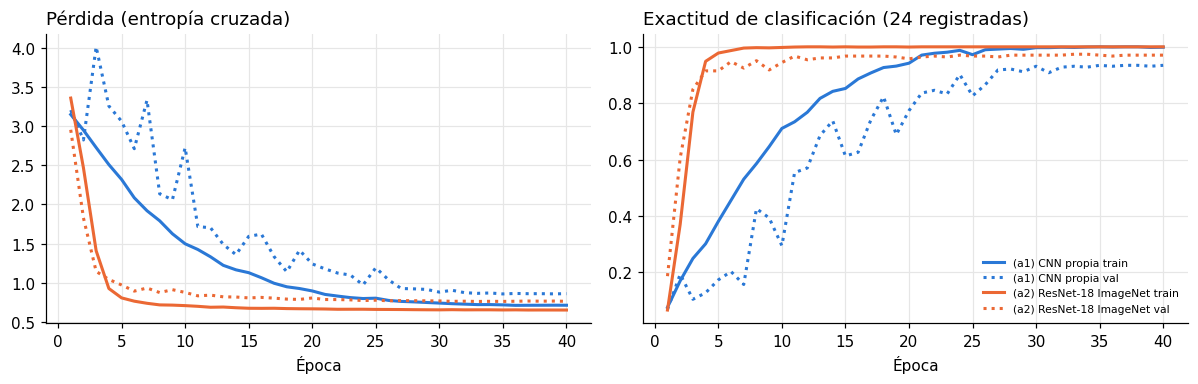

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for nombre, h in HIST.items():
    axes[0].plot(h.epoca, h.loss_train, color=COL[nombre], ls="-", lw=2, label=f"{NOMBRE[nombre]} train")
    axes[0].plot(h.epoca, h.loss_val, color=COL[nombre], ls=":", lw=2, label=f"{NOMBRE[nombre]} val")
    axes[1].plot(h.epoca, h.acc_train, color=COL[nombre], ls="-", lw=2, label=f"{NOMBRE[nombre]} train")
    axes[1].plot(h.epoca, h.acc_val, color=COL[nombre], ls=":", lw=2, label=f"{NOMBRE[nombre]} val")
axes[0].set_title("Pérdida (entropía cruzada)", loc="left"); axes[1].set_title("Exactitud de clasificación (24 registradas)", loc="left")
for a in axes: a.set_xlabel("Época")
axes[1].legend(frameon=False, fontsize=7, loc="lower right"); plt.tight_layout()
plt.savefig(C.FIGS / "03_curvas_entrenamiento_a.png"); plt.show()
pd.concat({k: v for k, v in HIST.items()}).to_csv(C.DOCS / "03_historial_entrenamiento_a.csv")

## 5. Comparación en validación

In [8]:
rows = []
for k in COL:
    r = RES[k]; t = TIEMPOS[k]
    rows.append({"variante": NOMBRE[k], "EER_%": r["EER"]*100, "EER_IC95_%": f"{r['EER_IC95_inf']*100:.2f}–{r['EER_IC95_sup']*100:.2f}",
                 "AUC": r["AUC"], "umbral_EER": r["umbral"], "FAR_%": r["FAR"]*100, "FRR_%": r["FRR"]*100,
                 "EER_internas_%": r["EER_internas"]*100,
                 "t_GPU_ms": t.get("GPU", (np.nan,))[0], "t_CPU_ms": t["CPU"][0], "t_CPU_p95_ms": t["CPU"][1],
                 "n_gen": r["n_genuinas"], "n_imp": r["n_impostoras"]})
tabla = pd.DataFrame(rows)
tabla.to_csv(C.DOCS / "03_comparacion_validacion.csv", index=False)
tabla.round(4)

,variante,EER_%,EER_IC95_%,AUC,umbral_EER,FAR_%,FRR_%,EER_internas_%,t_GPU_ms,t_CPU_ms,t_CPU_p95_ms,n_gen,n_imp
0,(a1) CNN propia,4.8521,3.93–6.57,0.9892,0.5495,4.7862,4.9180,2.8724,4.9066,19.9985,23.8243,305,6456
1,(a2) ResNet-18 ImageNet,3.5536,2.63–5.33,0.9929,0.7789,3.5006,3.6066,1.6251,6.5071,41.5829,55.6493,305,6456
2,(b1) FaceNet VGGFace2,0.0000,0.00–0.00,1.0000,0.6070,0.0000,0.0000,0.0000,32.8227,71.0281,91.5537,305,6456
3,(b2) FaceNet CASIA,0.6299,0.25–1.13,0.9999,0.4215,0.6041,0.6557,1.2117,36.1368,75.1575,114.5781,305,6456
4,(c) LBPH,33.5196,30.17–36.39,0.7171,-33.0850,33.5967,33.4426,28.5460,NaN,25.3893,37.1977,305,6456


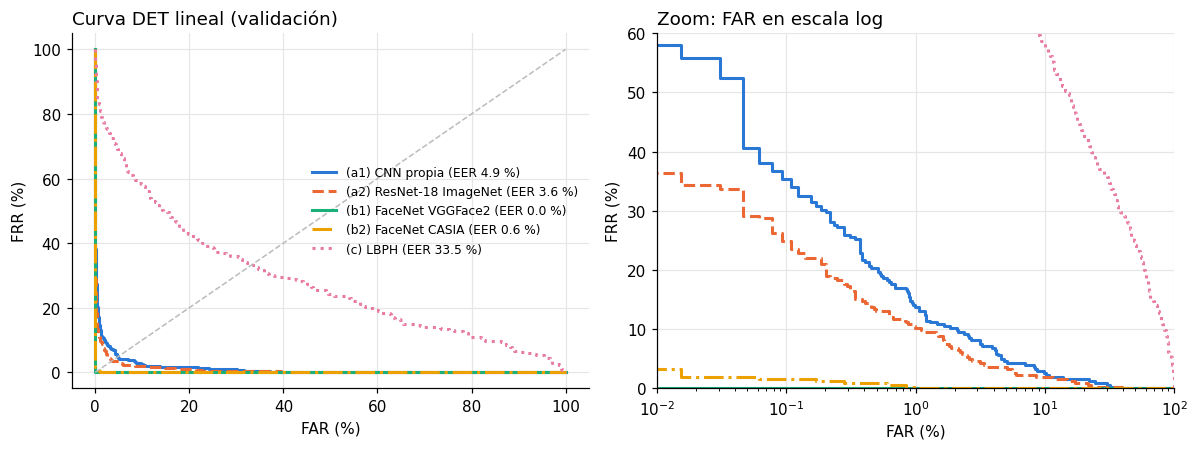

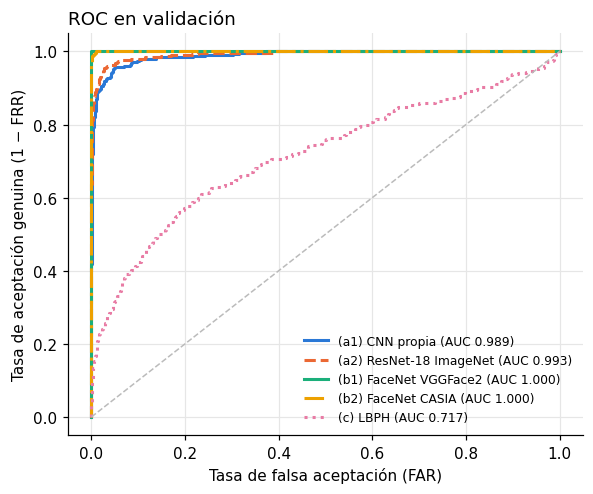

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for k in COL:
    fpr, tpr, _ = MT.roc(SCORES[k][1]["genuinas"], SCORES[k][1]["impostoras"])
    for a in axes:
        a.plot(fpr*100, (1-tpr)*100, color=COL[k], ls=LS[k], lw=2, label=f"{NOMBRE[k]} (EER {RES[k]['EER']*100:.1f} %)")
for a in axes:
    a.plot([0, 100], [0, 100], color="#bbb", lw=1, ls="--")
    a.set_xlabel("FAR (%)"); a.set_ylabel("FRR (%)")
axes[0].set_title("Curva DET lineal (validación)", loc="left"); axes[0].legend(frameon=False, fontsize=8)
axes[1].set_xscale("log"); axes[1].set_xlim(0.01, 100); axes[1].set_ylim(0, 60); axes[1].set_title("Zoom: FAR en escala log", loc="left")
plt.tight_layout(); plt.savefig(C.FIGS / "03_det_validacion.png"); plt.show()

fig, ax = plt.subplots(figsize=(5.5, 4.6))
for k in COL:
    fpr, tpr, _ = MT.roc(SCORES[k][1]["genuinas"], SCORES[k][1]["impostoras"])
    ax.plot(fpr, tpr, color=COL[k], ls=LS[k], lw=2, label=f"{NOMBRE[k]} (AUC {RES[k]['AUC']:.3f})")
ax.plot([0, 1], [0, 1], color="#bbb", lw=1, ls="--"); ax.set_xlabel("Tasa de falsa aceptación (FAR)"); ax.set_ylabel("Tasa de aceptación genuina (1 − FRR)")
ax.set_title("ROC en validación", loc="left"); ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(C.FIGS / "03_roc_validacion.png"); plt.show()

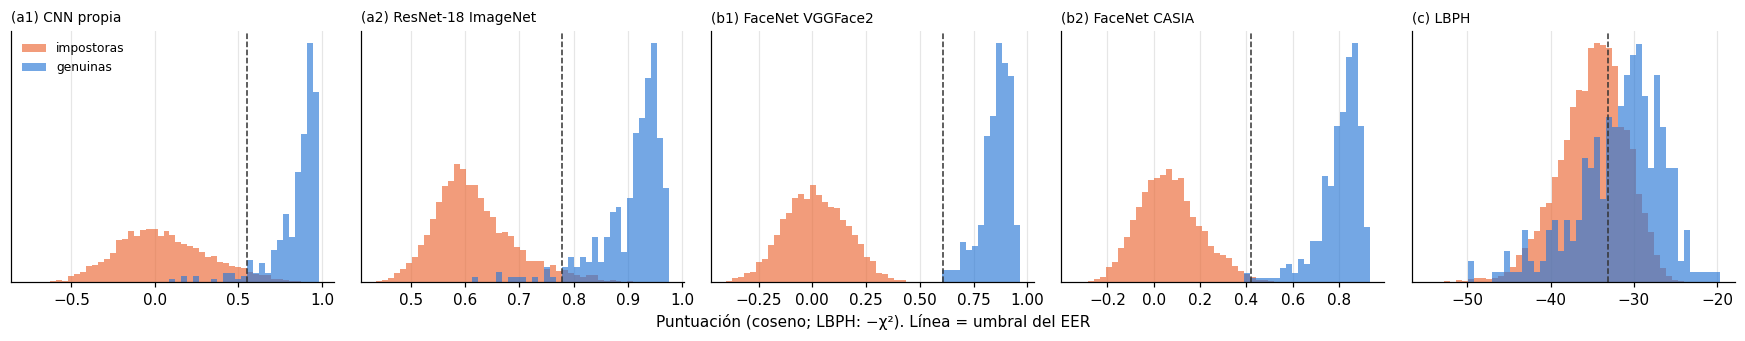

In [10]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.2))
for a, k in zip(axes, COL):
    sc = SCORES[k][1]
    lo = min(sc["genuinas"].min(), sc["impostoras"].min()); hi = max(sc["genuinas"].max(), sc["impostoras"].max())
    b = np.linspace(lo, hi, 50)
    a.hist(sc["impostoras"], bins=b, density=True, color="#eb6834", alpha=0.65, label="impostoras")
    a.hist(sc["genuinas"], bins=b, density=True, color="#2a78d6", alpha=0.65, label="genuinas")
    a.axvline(RES[k]["umbral"], color="#333", lw=1, ls="--")
    a.set_title(NOMBRE[k], loc="left", fontsize=9); a.set_yticks([])
axes[0].legend(frameon=False, fontsize=8); axes[2].set_xlabel("Puntuación (coseno; LBPH: −χ²). Línea = umbral del EER")
plt.tight_layout(); plt.savefig(C.FIGS / "03_distribucion_puntuaciones.png"); plt.show()

## 6. Chequeo del sesgo de famosos

Los modelos (b) se preentrenaron con colecciones de **celebridades** (VGGFace2, CASIA-WebFace) y probablemente vieron a casi todas las
identidades del dataset. Si fuera así, su rendimiento sería mejor con famosos que con personas desconocidas. Chequeos en validación:

1. **Marmik (registrada, no famosa)**: se miran sus 5 comparaciones genuinas con el umbral del EER global y su posición frente a la
   distribución genuina de los famosos.
2. **Impostora no famosa**: en validación **no hay ninguna**, porque Kashyap está reservada para prueba y no se toca aquí. Como sustituto,
   las 5 fotos de validación de Marmik se usan como **impostora no famosa interna** contra las otras 23 plantillas.
3. FRR por identidad registrada en el umbral del EER, para ver si Marmik destaca.

Con solo 5 fotos de Marmik, esto es una **señal cualitativa, no una prueba estadística**.

In [11]:
filas = []
mk = REG.index("Marmik")
for k in COL:
    S, sc = SCORES[k]; thr = RES[k]["umbral"]
    gp = sc["genuinas_pares"]; ip = sc["internas_pares"]
    probe_person = va.person.values
    g_mar = sc["genuinas"][probe_person[gp[:, 0]] == "Marmik"]
    g_fam = sc["genuinas"][probe_person[gp[:, 0]] != "Marmik"]
    i_mar = sc["internas"][probe_person[ip[:, 0]] == "Marmik"]          # Marmik se hace pasar por otras 23
    i_fam = sc["internas"][probe_person[ip[:, 0]] != "Marmik"]
    pct = (g_fam < np.median(g_mar)).mean() * 100
    filas.append({"variante": NOMBRE[k], "umbral_EER": thr,
                  "Marmik_genuinas_aceptadas": f"{(g_mar >= thr).sum()}/{len(g_mar)}",
                  "FRR_Marmik_%": (g_mar < thr).mean()*100, "FRR_famosos_%": (g_fam < thr).mean()*100,
                  "mediana_genuina_Marmik": np.median(g_mar), "mediana_genuina_famosos": np.median(g_fam),
                  "percentil_Marmik_en_genuinas_famosos": pct,
                  "FAR_Marmik_como_impostora_%": (i_mar >= thr).mean()*100, "n_Marmik_imp": len(i_mar),
                  "FAR_famosos_como_impostores_internos_%": (i_fam >= thr).mean()*100})
sesgo = pd.DataFrame(filas); sesgo.to_csv(C.DOCS / "03_chequeo_sesgo_famosos.csv", index=False); sesgo.round(3)

,variante,umbral_EER,Marmik_genuinas_aceptadas,FRR_Marmik_%,FRR_famosos_%,mediana_genuina_Marmik,mediana_genuina_famosos,percentil_Marmik_en_genuinas_famosos,FAR_Marmik_como_impostora_%,n_Marmik_imp,FAR_famosos_como_impostores_internos_%
0,(a1) CNN propia,0.550,5/5,0.0,5.000,0.915,0.900,57.667,0.000,115,0.855
1,(a2) ResNet-18 ImageNet,0.779,5/5,0.0,3.667,0.904,0.928,31.000,0.000,115,0.101
2,(b1) FaceNet VGGFace2,0.607,5/5,0.0,0.000,0.851,0.868,40.000,0.000,115,0.000
3,(b2) FaceNet CASIA,0.421,5/5,0.0,0.667,0.793,0.824,35.000,0.000,115,3.000
4,(c) LBPH,-33.085,2/5,60.0,33.000,-33.167,-30.792,32.667,1.739,115,21.928


In [12]:
frr_id = {}
for k in COL:
    S, sc = SCORES[k]; thr = RES[k]["umbral"]; gp = sc["genuinas_pares"]
    pp = va.person.values[gp[:, 0]]
    frr_id[NOMBRE[k]] = pd.Series({p: (sc["genuinas"][pp == p] < thr).mean()*100 for p in REG})
frr_id = pd.DataFrame(frr_id); frr_id["n_val"] = pd.Series(va[va_reg].person.value_counts())
frr_id.to_csv(C.DOCS / "03_frr_por_identidad_validacion.csv"); frr_id.round(1)

,(a1) CNN propia,(a2) ResNet-18 ImageNet,(b1) FaceNet VGGFace2,(b2) FaceNet CASIA,(c) LBPH,n_val
Akshay Kumar,0.0,0.0,0.0,0.0,12.5,8
Alexandra Daddario,0.0,0.0,0.0,0.0,13.3,15
Alia Bhatt,16.7,0.0,0.0,0.0,50.0,12
Amitabh Bachchan,0.0,0.0,0.0,0.0,0.0,11
Anushka Sharma,0.0,0.0,0.0,0.0,54.5,11
Billie Eilish,0.0,0.0,0.0,6.7,73.3,15
Brad Pitt,5.6,16.7,0.0,0.0,33.3,18
Camila Cabello,7.7,7.7,0.0,0.0,23.1,13
Charlize Theron,8.3,0.0,0.0,0.0,25.0,12
Claire Holt,6.7,13.3,0.0,6.7,40.0,15


In [13]:
json.dump({"resultados": RES, "tiempos_ms": TIEMPOS}, open(C.DOCS / "03_resultados_validacion.json", "w"), indent=2, default=float)
np.savez_compressed(C.DATA_PROCESSED / "tarea21_puntuaciones_val.npz", **{k: SCORES[k][0] for k in COL})
print("Guardado en", C.DOCS)

Guardado en D:\IA\FaceID\docs\sprint2


## 7. Conclusión (añadida tras la ejecución, sin volver a ejecutar)

- **Elegida: (b1) FaceNet InceptionResnetV1 con pesos VGGFace2**, embeddings y similitud coseno contra la plantilla.
  En validación obtiene EER 0,00 % y AUC 1,0000; la genuina mínima es 0,607 y la impostora máxima 0,511. Le siguen (b2) CASIA con 0,63 %,
  (a2) ResNet-18 ImageNet con 3,55 %, (a1) la CNN propia con 4,85 % y (c) LBPH con 33,5 %.
- La validación está **saturada** para (b1): con 0 errores, la regla del tres da un FRR ≤ ≈ 1 % y un FAR ≤ ≈ 0,05 % (95 %).
  El umbral del EER (0,607) queda en el borde del margen; el umbral operativo se fijará en la tarea 2.3.
- **Limitación:** VGGFace2 contiene celebridades, así que es probable que el modelo haya visto a las personas famosas del dataset y que el resultado
  sea optimista. Marmik (no famoso) es aceptado en 5/5 y rechazado como impostor en 115/115, pero son muy pocas muestras.
  El chequeo con una impostora no famosa (Kashyap) solo es posible en prueba (tarea 2.5).
- Detalle completo en `docs/sprint2/03_seleccion_tecnica.md`.